# Better features + cleaner target for the "toxic thread" classifier

Works on the files you already have: `reddit_text_10000_labeled.csv` (with `comment_toxicity` scores) and the raw `reddit_posts.csv`. **No re-scoring with toxic-bert is needed.**

**Fix 2: give the model more information**
- *Community and post metadata* (`community_name`, community size, posting hour/weekday, title/description length), joined back from the raw CSV because the cleaning step dropped them.
- *Early comments:* the text and toxicity scores of each post's first `EARLY_K` comments (by time) become features.

**Fix 3: a cleaner target**
- The label is computed **only from the later comments** (everything after the first `EARLY_K`), so features and label never share a comment (no leakage).
- A comment counts as toxic only above a stricter score (`COMMENT_THRESHOLD`, default 0.8), and a post is "toxic" only if it has at least `MIN_TOXIC_COUNT` such comments **and** at least `MIN_TOXIC_RATE` of its later comments. One borderline comment no longer flips a post.
- Non-English posts are dropped (toxic-bert is English-only, so their labels are unreliable).

The last section trains a quick model with three feature sets so you can see which fix actually helps. It reports ROC-AUC and average precision (threshold-free) as well as F1.

**Caveat:** the early-comment features mean this predicts toxicity *after the first few comments arrive*, not from the title alone. Community popularity numbers such as final upvotes or total comment count are available but off by default, because they are only known after a thread has played out.

In [15]:
%pip install -q langdetect scikit-learn pandas numpy tqdm


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [16]:
import json
import numpy as np
import pandas as pd
from tqdm.auto import tqdm

# ---------------- CONFIG ----------------
LABELED_CSV  = "reddit_text_10000_labeled.csv"   # output of data-labeling.ipynb
RAW_CSV      = "reddit_posts.csv"                # original export (has community_name etc.)
OUTPUT_CSV   = "reddit_text_10000_features.csv"  # modeling table written at the end

EARLY_K          = 5      # first K comments (by time) are used as features
MIN_LATER        = 5      # a post needs at least this many comments AFTER the first K to get a label
COMMENT_THRESHOLD = 0.8   # a comment is "toxic" if its toxic-bert score is >= this (was 0.5)
MIN_TOXIC_COUNT  = 2      # post is toxic if it has at least this many toxic later comments ...
MIN_TOXIC_RATE   = 0.10   # ... AND at least this share of its later comments are toxic

ENGLISH_ONLY     = True   # drop posts detected as another language (unclear/short text is kept)
USE_POPULARITY_FEATURES = False  # final upvotes / total comments: only known AFTER the thread plays out

SEED = 42
# ----------------------------------------

## Step 1: Load the labeled posts and parse the comment lists
`comments` and `comment_toxicity` are JSON lists of the same length, in time order (the cleaning step sorted them chronologically).

In [17]:
data = pd.read_csv(LABELED_CSV, dtype=str, keep_default_na=False)
data["comment_list"] = data["comments"].apply(json.loads)
data["score_list"]   = data["comment_toxicity"].apply(json.loads)
assert (data["comment_list"].apply(len) == data["score_list"].apply(len)).all(), "comments and scores are misaligned"

def text_key(title, description):
    # same normalization your classifier uses to group duplicate posts
    s = title.fillna("").astype(str) + " " + description.fillna("").astype(str)
    return s.str.lower().str.replace(r"\s+", " ", regex=True).str.strip()

data["key"] = text_key(data["title"], data["description"])
data["post_text"] = data["title"] + " " + data["description"]
print(f"{len(data):,} labeled posts loaded")
funnel = [("loaded", len(data))]

10,000 labeled posts loaded


## Step 2 (fix 2a): Join community and post metadata back from the raw CSV
The labeled file has no `post_id`, so posts are matched on their normalized title + description. The raw file is read in chunks and only matching rows are kept. If some text appears in several communities (crossposts), the community is set to unknown for that post.

*Tip for future runs:* keep `post_id` in the cleaning export (`export_data = filtered_data[["post_id", "title", "description"]]...`) and this join becomes exact.

In [18]:
META_COLS = ["post_id", "title", "description", "community_name", "community_members_num",
             "date_posted", "num_upvotes", "num_comments"]
wanted = set(data["key"])
parts = []
reader = pd.read_csv(RAW_CSV, usecols=lambda c: c in META_COLS, dtype=str, keep_default_na=False, chunksize=50_000)
for chunk in tqdm(reader, desc="Scanning raw CSV"):
    chunk["key"] = text_key(chunk["title"], chunk["description"])
    parts.append(chunk[chunk["key"].isin(wanted)])
meta = pd.concat(parts, ignore_index=True)

# crossposts: same text in different communities -> community unknown
n_communities = meta.groupby("key")["community_name"].nunique()
conflicting = set(n_communities[n_communities > 1].index)
meta = meta.drop_duplicates("key", keep="first").copy()
meta.loc[meta["key"].isin(conflicting), "community_name"] = ""
meta = meta.drop(columns=["title", "description"])

data = data.merge(meta, on="key", how="left")
match_rate = data["post_id"].notna().mean()
print(f"Matched metadata for {match_rate:.1%} of posts ({len(conflicting)} texts appear in several communities)")
if match_rate < 0.9:
    print("WARNING: low match rate. Check that RAW_CSV is the file the labeled sample came from.")

Scanning raw CSV: 5it [00:14,  2.90s/it]

Matched metadata for 100.0% of posts (24 texts appear in several communities)


In [19]:
# Features known at posting time
data["community_name"] = data["community_name"].fillna("").replace("", "unknown")
dt = pd.to_datetime(data["date_posted"], errors="coerce", utc=True)
data["post_hour"]    = dt.dt.hour.astype("Int64").astype(str)       # "<NA>" when the date is missing
data["post_weekday"] = dt.dt.dayofweek.astype("Int64").astype(str)

num = lambda col: pd.to_numeric(data[col], errors="coerce")
data["title_words_log"] = np.log1p(data["title"].str.split().str.len())
data["desc_words_log"]  = np.log1p(data["description"].str.split().str.len())
data["title_has_q"]     = data["title"].str.contains(r"\?", regex=True).astype(int)
data["community_size_log"] = np.log1p(num("community_members_num").fillna(0).clip(lower=0))

# Only known after the thread has played out (off by default)
data["post_upvotes_log"]  = np.log1p(num("num_upvotes").fillna(0).clip(lower=0))
data["total_comments_log"] = np.log1p(num("num_comments").fillna(0).clip(lower=0))

print(data["community_name"].value_counts().head(8))
funnel.append(("metadata joined", int(data["post_id"].notna().sum())))

community_name
personalfinance          693
TrueUnpopularOpinion     463
PersonalFinanceCanada    409
AmItheAsshole            400
UKPersonalFinance        293
povertyfinance           286
recruitinghell           272
changemyview             263
Name: count, dtype: int64


## Step 3 (fix 3a): Drop non-English posts
`toxic-bert` was trained on English text, so its scores for other languages are unreliable and would add label noise. Detection runs on the post text; very short or unclear text is kept rather than guessed. On the full 188k posts this takes a few minutes.

In [20]:
from langdetect import detect_langs, DetectorFactory, LangDetectException
DetectorFactory.seed = 0

def detect_lang(text):
    try:
        best = detect_langs(text[:600])[0]
    except LangDetectException:
        return "unknown"
    return best.lang if best.prob >= 0.8 else "unknown"

data["lang"] = [detect_lang(t) for t in tqdm(data["post_text"], desc="Detecting language")]
print(data["lang"].value_counts().head(8))
if ENGLISH_ONLY:
    data = data[data["lang"].isin(["en", "unknown"])].copy()
funnel.append(("after language filter", len(data)))

Detecting language: 100%|██████████| 10000/10000 [00:07<00:00, 1381.99it/s]

lang
en         9414
tl          162
it           95
unknown      58
ro           55
es           35
ar           34
el           34
Name: count, dtype: int64


## Step 4 (fix 2b + 3b): Split comments into early (features) and later (target)
- `early_*` columns describe the first `EARLY_K` comments: their text and their toxicity scores.
- The target uses **only** the later comments, with the stricter rule from the config.
The table shows how many posts end up positive under different rules, so you can pick a balance you are happy with (roughly 10 to 25% positive works well).

In [21]:
def make_target(later_scores, threshold, min_count, min_rate):
    n_toxic = sum(s >= threshold for s in later_scores)
    return int(n_toxic >= min_count and n_toxic / len(later_scores) >= min_rate)

data["n_comments_list"] = data["score_list"].apply(len)
data = data[data["n_comments_list"] >= EARLY_K + MIN_LATER].copy()
funnel.append((f"at least {EARLY_K + MIN_LATER} comments", len(data)))

early_scores = data["score_list"].apply(lambda s: s[:EARLY_K])
later_scores = data["score_list"].apply(lambda s: s[EARLY_K:])

# early-comment features
data["early_text"]        = data["comment_list"].apply(lambda c: " \n ".join(c[:EARLY_K]))
data["early_max"]         = early_scores.apply(max)
data["early_mean"]        = early_scores.apply(np.mean)
data["early_n_toxic"]     = early_scores.apply(lambda s: sum(x >= 0.5 for x in s))
data["early_n_toxic_hi"]  = early_scores.apply(lambda s: sum(x >= COMMENT_THRESHOLD for x in s))
data["early_chars_log"]   = np.log1p(data["early_text"].str.len())

# target from LATER comments only
data["n_later"]        = later_scores.apply(len)
data["n_toxic_later"]  = later_scores.apply(lambda s: sum(x >= COMMENT_THRESHOLD for x in s))
data["toxic_target"]   = [make_target(s, COMMENT_THRESHOLD, MIN_TOXIC_COUNT, MIN_TOXIC_RATE) for s in later_scores]

print(pd.DataFrame(funnel, columns=["step", "posts"]).to_string(index=False))
print(f"\nPositive rate with the chosen rule: {data['toxic_target'].mean():.1%} "
      f"({int(data['toxic_target'].sum())} of {len(data)} posts)\n")

rows = [{"comment_threshold": t, "min_toxic_count": c,
         "positive_rate": np.mean([make_target(s, t, c, MIN_TOXIC_RATE) for s in later_scores])}
        for t in (0.5, 0.8, 0.9) for c in (1, 2, 3)]
print(f"Positive rate for other rules (min toxic share fixed at {MIN_TOXIC_RATE:.0%}):")
print(pd.DataFrame(rows).pivot(index="comment_threshold", columns="min_toxic_count", values="positive_rate").round(3))

                 step  posts
               loaded  10000
      metadata joined  10000
after language filter   9472
 at least 10 comments   7391

Positive rate with the chosen rule: 10.1% (743 of 7391 posts)

Positive rate for other rules (min toxic share fixed at 10%):
min_toxic_count        1      2      3
comment_threshold                     
0.5                0.234  0.185  0.090
0.8                0.133  0.101  0.037
0.9                0.087  0.062  0.019


## Step 5: Does it help? Compare feature sets on the same split
Duplicate posts stay on the same side of the train/test split. The decision threshold is chosen from cross-validated predictions on the **training** set only, then applied to the test set. Compare ROC-AUC and average precision to the "random guessing" row; accuracy is shown only for reference because always predicting "not toxic" already scores `1 - positive rate`.

In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedGroupKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

df = data.reset_index(drop=True)
y = df["toxic_target"]

# group-aware split (same idea as your notebook)
group_label = df.groupby("key")["toxic_target"].max()
train_groups, test_groups = train_test_split(group_label.index.to_numpy(), test_size=0.2,
                                             random_state=SEED, stratify=group_label)
train_mask = df["key"].isin(train_groups).to_numpy()
test_mask  = df["key"].isin(test_groups).to_numpy()
print(f"train posts: {train_mask.sum()}  test posts: {test_mask.sum()}  (positive rate {y.mean():.1%})")

CAT_COLS   = ["community_name", "post_hour", "post_weekday"]
META_NUM   = ["title_words_log", "desc_words_log", "title_has_q", "community_size_log"]
if USE_POPULARITY_FEATURES:
    META_NUM += ["post_upvotes_log", "total_comments_log"]
EARLY_NUM  = ["early_max", "early_mean", "early_n_toxic", "early_n_toxic_hi", "early_chars_log"]

def build_pipeline(use_meta, use_early, C=1.0):
    blocks = [("post_text", TfidfVectorizer(min_df=2, max_features=30000, sublinear_tf=True), "post_text")]
    if use_meta:
        blocks += [("community_time", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10), CAT_COLS),
                   ("meta_num", StandardScaler(), META_NUM)]
    if use_early:
        blocks += [("early_text", TfidfVectorizer(min_df=2, max_features=20000, sublinear_tf=True), "early_text"),
                   ("early_num", StandardScaler(), EARLY_NUM)]
    return Pipeline([("features", ColumnTransformer(blocks)),
                     ("clf", LogisticRegression(C=C, class_weight="balanced", max_iter=3000))])

def run_experiment(name, use_meta, use_early):
    X_tr, X_te = df.loc[train_mask], df.loc[test_mask]
    y_tr, y_te = y[train_mask], y[test_mask]
    pipe = build_pipeline(use_meta, use_early)

    # choose the decision threshold on cross-validated TRAIN predictions (never on the test set)
    cv = StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=SEED)
    cv_scores = cross_val_predict(pipe, X_tr, y_tr, groups=X_tr["key"], cv=cv, method="decision_function")
    prec, rec, thr = precision_recall_curve(y_tr, cv_scores)
    f1s = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-12)
    best_thr = thr[int(np.argmax(f1s))]

    pipe.fit(X_tr, y_tr)
    pipe.reddit_threshold_ = float(best_thr)
    s = pipe.decision_function(X_te)
    pred = (s >= best_thr).astype(int)
    result = {"features": name,
              "ROC-AUC": roc_auc_score(y_te, s),
              "avg_precision": average_precision_score(y_te, s),
              "F1": f1_score(y_te, pred, zero_division=0),
              "precision": precision_score(y_te, pred, zero_division=0),
              "recall": recall_score(y_te, pred, zero_division=0),
              "accuracy": accuracy_score(y_te, pred)}
    return result, pipe

experiments = [("A: post text only", False, False),
               ("B: + community, time, length", True, False),
               ("C: + early comments", True, True)]
results, fitted = [], {}
for name, use_meta, use_early in experiments:
    r, p = run_experiment(name, use_meta, use_early)
    results.append(r); fitted[name] = p

# ---------------- EXPORT DEPLOYMENT MODEL ----------------

import joblib
import os

MODEL_NAME = "reddit_toxicity_deployment.pkl"

# Use the full model: post text + metadata + first five comments
deployment_model = fitted["C: + early comments"]

# Confirm that the threshold was saved
assert hasattr(deployment_model, "reddit_threshold_"), \
    "Decision threshold missing. Add pipe.reddit_threshold_ = float(best_thr) inside run_experiment()."

# Save the model and its threshold together
joblib.dump(deployment_model, MODEL_NAME)

print("Model exported successfully!")
print(f"Model: {MODEL_NAME}")
print(f"Decision threshold: {deployment_model.reddit_threshold_:.6f}")
print(f"Pipeline: {deployment_model}")

# ------------------------------------------------------------------------

y_test_rate = y[test_mask].mean()
results.append({"features": "random guessing / always 'not toxic'", "ROC-AUC": 0.5, "avg_precision": y_test_rate,
                "F1": np.nan, "precision": np.nan, "recall": np.nan, "accuracy": 1 - y_test_rate})
pd.DataFrame(results).set_index("features").round(3)

train posts: 5917  test posts: 1474  (positive rate 10.1%)
Model exported successfully!
Model: reddit_toxicity_deployment.pkl
Decision threshold: 0.254952
Pipeline: Pipeline(steps=[('features',
                 ColumnTransformer(transformers=[('post_text',
                                                  TfidfVectorizer(max_features=30000,
                                                                  min_df=2,
                                                                  sublinear_tf=True),
                                                  'post_text'),
                                                 ('community_time',
                                                  OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                min_frequency=10),
                                                  ['community_name',
                                                   'post_hour',
                                             

,ROC-AUC,avg_precision,F1,precision,recall,accuracy
features,,,,,,
A: post text only,0.787,0.270,0.370,0.282,0.541,0.815
"B: + community, time, length",0.799,0.293,0.396,0.289,0.628,0.807
C: + early comments,0.814,0.301,0.384,0.337,0.446,0.856
random guessing / always 'not toxic',0.500,0.100,NaN,NaN,NaN,0.900


### Is the improvement real? Repeat with several random splits
One split can look better or worse by luck, especially with a small test set. This cell repeats the comparison on 5 different splits. **Lift** is average precision divided by the positive rate (1.0 = no better than guessing). Trust a feature set only if its lead over the one before it is bigger than the spread (`std`) across splits.

In [23]:
seed_rows = []
for split_seed in range(5):
    tg, eg = train_test_split(group_label.index.to_numpy(), test_size=0.2,
                              random_state=split_seed, stratify=group_label)
    train_mask = df["key"].isin(tg).to_numpy()      # run_experiment reads these two masks
    test_mask  = df["key"].isin(eg).to_numpy()
    base_rate = y[test_mask].mean()
    for name, use_meta, use_early in experiments:
        r, _ = run_experiment(name, use_meta, use_early)
        seed_rows.append({"split": split_seed, **r, "lift": r["avg_precision"] / base_rate})

repeat = pd.DataFrame(seed_rows)
summary = repeat.groupby("features")[["ROC-AUC", "avg_precision", "lift", "F1"]].agg(["mean", "std"]).round(3)
summary

ROC-AUC        avg_precision          lift  \
                                mean    std          mean    std   mean   
features                                                                  
A: post text only              0.807  0.013         0.302  0.028  3.003   
B: + community, time, length   0.824  0.016         0.324  0.019  3.221   
C: + early comments            0.842  0.015         0.349  0.024  3.465   

                                        F1         
                                std   mean    std  
features                                           
A: post text only             0.276  0.376  0.027  
B: + community, time, length  0.184  0.401  0.021  
C: + early comments           0.224  0.423  0.020

In [24]:
# Which features push a post toward "toxic" in the full model?
full = fitted["C: + early comments"]
names = full.named_steps["features"].get_feature_names_out()
weights = pd.Series(full.named_steps["clf"].coef_[0], index=names).sort_values()
print("Strongest toxic-thread signals:")
print(weights.tail(15).round(3).to_string())
print("\nStrongest calm-thread signals:")
print(weights.head(10).round(3).to_string())

Strongest toxic-thread signals:
early_text__to                                         1.247
community_time__community_name_SoftwareEngineerJobs    1.257
community_time__community_name_homeless                1.265
early_text__this                                       1.281
early_text__republicans                                1.290
community_time__community_name_whennews                1.403
post_text__finish                                      1.465
early_text__doesn                                      1.484
community_time__community_name_stlucianews             1.488
early_text__he                                         1.515
early_text__her                                        1.592
early_text__she                                        1.811
early_text__anyone                                     1.902
community_time__community_name_NewsomMassacre          1.913
post_text__trump                                       3.030

Strongest calm-thread signals:
early_text__thank    

In [25]:
drop = ["comment_list", "score_list", "n_comments_list"]
df.drop(columns=drop).to_csv(OUTPUT_CSV, index=False)
print(f"Saved {len(df):,} posts to {OUTPUT_CSV}")

Saved 7,391 posts to reddit_text_10000_features.csv


## Reading the results and next steps
- If **B** beats **A**, community and timing matter, so keep them. If **C** beats **B**, early comments carry real signal about how a thread will go.
- If all three have ROC-AUC near 0.5, the target is mostly noise. Loosen it (lower `MIN_TOXIC_COUNT`, or `COMMENT_THRESHOLD` of 0.5) or label more posts.
- Small data means noisy metrics. Re-run with a different `SEED` and check the numbers are stable before drawing conclusions.
- When you have these features working, replace the logistic regression with sentence embeddings or a gradient-boosted model, and run the same pipeline on more than 10,000 posts.
- Posts must have at least `EARLY_K + MIN_LATER` comments to get a label, so results describe posts that attract some discussion.

In [26]:
tg, eg = train_test_split(group_label.index.to_numpy(), test_size=0.2, random_state=SEED, stratify=group_label)
test_mask = df["key"].isin(eg).to_numpy()          # same split the models were trained against

scores = fitted["C: + early comments"].decision_function(df.loc[test_mask])
y_te = y[test_mask].to_numpy()
for share in (0.05, 0.10, 0.20):
    top = np.argsort(-scores)[: max(1, int(share * len(scores)))]
    print(f"Top {share:.0%} of posts by score: {y_te[top].mean():.1%} are toxic "
          f"(overall rate {y_te.mean():.1%}); catches {y_te[top].sum() / y_te.sum():.0%} of all toxic posts")

Top 5% of posts by score: 39.7% are toxic (overall rate 10.0%); catches 20% of all toxic posts
Top 10% of posts by score: 33.3% are toxic (overall rate 10.0%); catches 33% of all toxic posts
Top 20% of posts by score: 28.9% are toxic (overall rate 10.0%); catches 57% of all toxic posts


,features,ROC-AUC,avg_precision,F1,precision,recall,accuracy
class_weight,,,,,,,
None,C: + early comments,0.952,0.761,0.650,0.546,0.804,0.913
balanced,C: + early comments,0.966,0.834,0.657,0.520,0.892,0.906
1:5,C: + early comments,0.970,0.889,0.704,0.581,0.892,0.925
1:10,C: + early comments,0.971,0.899,0.693,0.567,0.892,0.921
1:20,C: + early comments,0.972,0.903,0.702,0.579,0.892,0.924
1:30,C: + early comments,0.972,0.902,0.632,0.484,0.912,0.893
1:40,C: + early comments,0.972,0.903,0.644,0.498,0.912,0.899
1:50,C: + early comments,0.972,0.902,0.691,0.558,0.905,0.919
1:60,C: + early comments,0.972,0.903,0.689,0.556,0.905,0.918


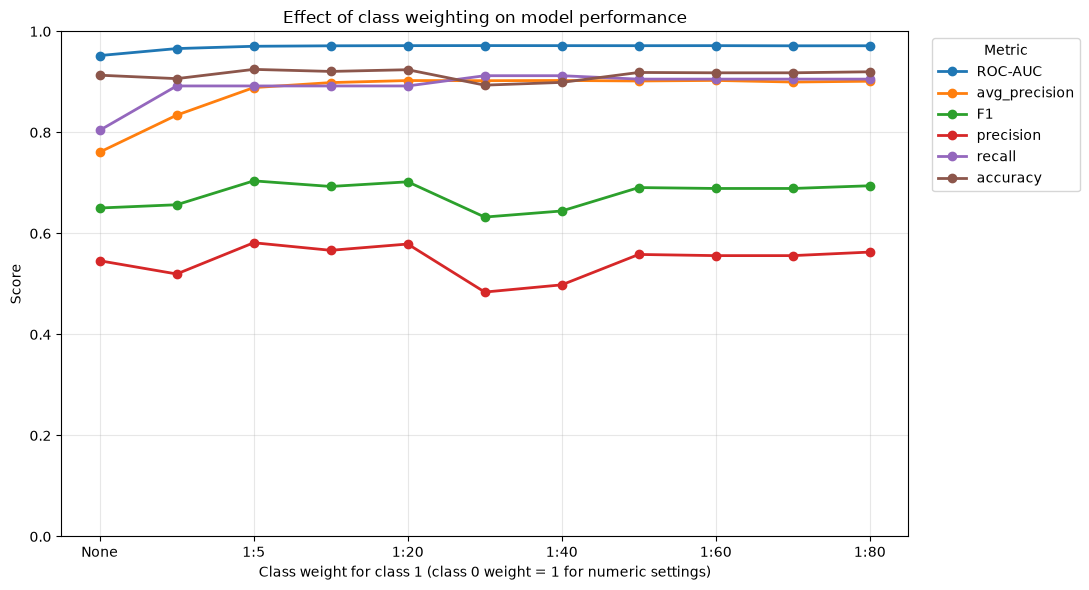

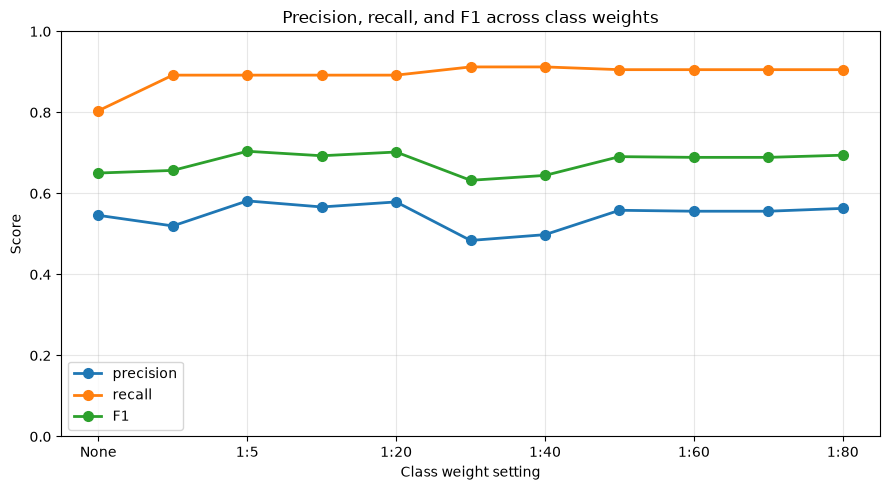

Best F1: 1:5 (0.704)
Best average precision: 1:60 (0.903)


In [30]:
# Compare class-weight settings for the full feature model.
# This reuses the same train/test split and chooses each threshold using CV on TRAIN only.

import matplotlib.pyplot as plt

if "_orig_build" not in globals():
    _orig_build = build_pipeline  # preserve the original pipeline builder

CLASS_WEIGHT = "balanced"

def build_pipeline(use_meta, use_early, C=1.0):
    pipe = _orig_build(use_meta, use_early, C)
    pipe.set_params(clf__class_weight=CLASS_WEIGHT)
    return pipe

weight_tests = [
    ("None", None),
    ("balanced", "balanced"),
    ("1:5",  {0: 1, 1: 5}),
    ("1:10", {0: 1, 1: 10}),
    ("1:20", {0: 1, 1: 20}),
    ("1:30", {0: 1, 1: 30}),
    ("1:40", {0: 1, 1: 40}),
    ("1:50", {0: 1, 1: 50}),
    ("1:60", {0: 1, 1: 60}),
    ("1:70", {0: 1, 1: 70}),
    ("1:80", {0: 1, 1: 80}),
]

weight_rows = []
weight_models = {}

for label, class_weight in weight_tests:
    CLASS_WEIGHT = class_weight
    result, fitted_model = run_experiment("C: + early comments", True, True)
    weight_rows.append({"class_weight": label, **result})
    weight_models[label] = fitted_model

weight_results = pd.DataFrame(weight_rows).set_index("class_weight")
display(weight_results.round(3))

# Plot all evaluation metrics so you can see the trade-offs as class 1 gets more weight.
metrics_to_plot = [
    "ROC-AUC", "avg_precision", "F1",
    "precision", "recall", "accuracy"
]

ax = weight_results[metrics_to_plot].plot(
    kind="line", marker="o", figsize=(11, 6), ylim=(0, 1),
    linewidth=2, markersize=6
)
ax.set_title("Effect of class weighting on model performance")
ax.set_xlabel("Class weight for class 1 (class 0 weight = 1 for numeric settings)")
ax.set_ylabel("Score")
ax.grid(True, alpha=0.3)
ax.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# A focused plot makes the precision/recall trade-off easier to inspect.
ax = weight_results[["precision", "recall", "F1"]].plot(
    kind="line", marker="o", figsize=(9, 5), ylim=(0, 1),
    linewidth=2, markersize=7
)
ax.set_title("Precision, recall, and F1 across class weights")
ax.set_xlabel("Class weight setting")
ax.set_ylabel("Score")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Remove duplicate class-weight index entries, if any
weight_results = weight_results[~weight_results.index.duplicated(keep="last")]

best_f1_setting = weight_results["F1"].idxmax()
best_ap_setting = weight_results["avg_precision"].idxmax()

print(
    f"Best F1: {best_f1_setting} "
    f"({weight_results.loc[best_f1_setting, 'F1']:.3f})"
)

print(
    f"Best average precision: {best_ap_setting} "
    f"({weight_results.loc[best_ap_setting, 'avg_precision']:.3f})"
)


Save the model

In [31]:
import joblib

best_model = weight_models["1:20"]

joblib.dump(
    best_model,
    "reddit_toxicity_model.pkl"
)

joblib.dump(
    COMMENT_THRESHOLD,
    "reddit_threshold.pkl"
)

['reddit_threshold.pkl']